# CRISP-DM Stage 1: Business & Application Understanding
## ECG Heartbeat Classification on Edge-AI (Analog Devices MAX78002)

---

### Executive Summary
Cardiovascular diseases (CVDs) remain the leading cause of death globally, taking an estimated 17.9 million lives each year according to the World Health Organization (WHO). Among cardiac disorders, cardiac arrhythmias—disruptions in the heart's normal electrical rhythm—can range from benign irregularities to acutely life-threatening conditions such as ventricular tachycardia (VT) and ventricular fibrillation (VF).

Early and continuous detection is vital. Traditional clinical Holter monitors require recording data over 24–48 hours for offline interpretation by cardiologists, delaying diagnosis. Emerging wearable Edge-AI devices enable real-time, on-body screening and timely triage, alerting patients and medical personnel to malignant ectopic events instantly.

In this project, we develop a compact, robust deep learning model for **4-class ECG heartbeat classification** strictly designed for deployment on the **Analog Devices MAX78002 Edge-AI microcontroller**.

In [1]:
# Environment Setup & Utility Imports
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.style.use('seaborn-v0_8-whitegrid')

print("Task 1 Environment Loaded Successfully.")

Task 1 Environment Loaded Successfully.


## 1.1 Application Scenario

### What problem are we trying to solve?
The core challenge is accurately detecting and categorizing abnormal heartbeats (arrhythmias) from single-lead ambulatory electrocardiogram (ECG) signals in real time on an ultra-low-power, resource-constrained edge device.

Real-world ambulatory ECGs are subject to:
- Severe patient-to-patient morphological variation (biometric variability).
- Pervasive environmental artifacts (baseline wander from breathing, electromyographic muscle tremors, electrode motion).
- Extreme class imbalance where healthy sinus beats outnumber rare, life-threatening ventricular or fusion beats by over $100:1$.

### Where could automatic ECG classification be useful?
1. **Wearable Cardiac Monitors (Smartwatches, Chest Patches)**: Continuous, ambulatory monitoring for outpatients at risk of sudden cardiac arrest.
2. **Post-Operative Triage & ICU Telemetry**: Real-time alarm systems alerting nurses immediately upon detection of ventricular ectopic runs.
3. **Remote Patient Monitoring (Rural / Low-Resource Settings)**: Automated screening in remote healthcare centers where cardiologists are not physically present.
4. **Implantable Cardiac Monitors (ICMs)**: Ultra-low-power event recorders monitoring for intermittent syncope and occult atrial fibrillation.

### Why inference directly on an Edge-AI device?
Traditional wearable devices stream raw ECG sensor data to the cloud or a smartphone via Bluetooth Low Energy (BLE) or Wi-Fi. However, continuous wireless transmission has severe drawbacks:
- **Excessive Power Consumption**: Wireless radio transmission consumes $10\times - 50\times$ more energy per bit than local hardware CNN inference.
- **Latency & Reliability**: Emergency arrhythmias (such as runs of PVCs degenerating into ventricular fibrillation) require sub-second alerting; network packet loss, disconnections, or lack of cellular coverage can lead to fatal delays.
- **Patient Privacy**: Streaming raw biometric physiological data over public networks poses regulatory (HIPAA, GDPR) and privacy risks. On-device inference keeps sensitive data local, transmitting only aggregated clinical alerts.

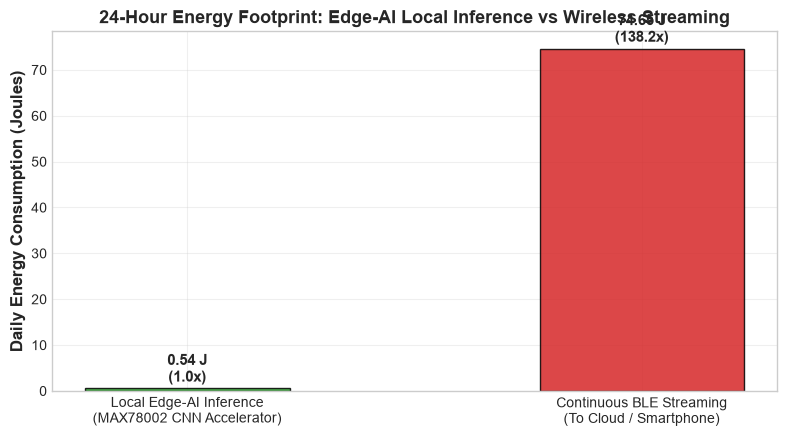

Total 24h Heartbeats     : 108,000
Local Edge Inference     : 0.540 Joules / day
Continuous BLE Streaming : 74.650 Joules / day (138.2x more energy!)


In [2]:
# Comparative Analysis: Edge-AI Inference vs Wireless Cloud Streaming
# Simulating energy consumption over 24 hours of continuous ECG monitoring

hours = 24
sampling_rate = 360  # Hz
bytes_per_sample = 2  # 16-bit ADC
total_samples_day = 360 * 3600 * hours
total_bytes_day = total_samples_day * bytes_per_sample
heartbeats_per_day = 75 * 60 * hours  # ~108,000 beats assuming 75 bpm

# Energy parameters (typical industry values for MAX78002 vs BLE streaming)
# MAX78002 CNN hardware accelerator: ~5 microjoules (uJ) per 1D CNN inference
energy_per_inference_uJ = 5.0
energy_cnn_day_joules = (heartbeats_per_day * energy_per_inference_uJ) / 1e6

# BLE streaming: ~0.15 microjoules per bit transmitted (~1.2 uJ per byte)
energy_per_byte_ble_uJ = 1.2
energy_ble_day_joules = (total_bytes_day * energy_per_byte_ble_uJ) / 1e6

fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ['Local Edge-AI Inference\n(MAX78002 CNN Accelerator)', 'Continuous BLE Streaming\n(To Cloud / Smartphone)']
energies = [energy_cnn_day_joules, energy_ble_day_joules]
colors = ['#2ca02c', '#d62728']

bars = ax.bar(categories, energies, color=colors, width=0.45, alpha=0.85, edgecolor='black')
ax.set_ylabel("Daily Energy Consumption (Joules)", fontweight='bold')
ax.set_title("24-Hour Energy Footprint: Edge-AI Local Inference vs Wireless Streaming", fontweight='bold')
ax.grid(True, alpha=0.3)

for bar, val in zip(bars, energies):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1.5, f"{val:.2f} J\n({val/energy_cnn_day_joules:.1f}x)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Total 24h Heartbeats     : {heartbeats_per_day:,}")
print(f"Local Edge Inference     : {energy_cnn_day_joules:.3f} Joules / day")
print(f"Continuous BLE Streaming : {energy_ble_day_joules:.3f} Joules / day ({(energy_ble_day_joules / energy_cnn_day_joules):.1f}x more energy!)")

## 1.2 Data-Mining Objective

The machine learning problem is formulated as **multiclass single-lead supervised heartbeat classification**:

| Item | Technical Description |
| :--- | :--- |
| **Input ($\mathbf{x}$)** | Fixed-size single-channel 1D ECG segment of **256 samples** ($711.1\text{ ms}$ @ $360\text{ Hz}$), centered on the R-peak ($90$ samples pre-R, $166$ samples post-R), Z-score normalized and clamped to $[-3.0, 3.0]$. Shape: $(1, 256)$ |
| **Output ($\hat{y}$)** | Predicted class probability distribution over the 4 AAMI EC57 heartbeat classes: $\hat{y} \in \{\text{N}, \text{S}, \text{V}, \text{F}\}$ |
| **Type of Task** | Supervised 4-Class Classification under severe class imbalance and inter-patient distribution shift |

### Mathematical Formulation
Given an ECG lead signal $s[n]$, an annotated or detected R-peak at index $r_k$, we extract a discrete heartbeat window:
$$\mathbf{x}_k = [s[r_k - 90], s[r_k - 89], \dots, s[r_k + 165]]^T \in \mathbb{R}^{256}$$
After bandpass filtering and per-beat Z-score normalization, the neural network learns a parameterized function:
$$f_\theta: \mathbb{R}^{256} \to \Delta^3$$
where $\Delta^3 = \{ \mathbf{p} \in [0, 1]^4 \mid \sum_{c=1}^4 p_c = 1\}$ denotes the probability simplex across classes $\{N, S, V, F\}$.

In [3]:
# Formal Data-Mining Objective Representation
objective_df = pd.DataFrame([
    {"Item": "Input", "Specification": "Single-lead ECG (MLII), 256 samples (711 ms @ 360 Hz), shape (1, 256), INT8/FP32"},
    {"Item": "Output", "Specification": "Predicted class label in {N, S, V, F} with softmax confidence scores"},
    {"Item": "Task Type", "Specification": "Multiclass supervised classification with severe class imbalance"},
    {"Item": "Platform", "Specification": "Analog Devices MAX78002 CNN hardware accelerator"}
])
display(objective_df)

,Item,Specification
0,Input,"Single-lead ECG (MLII), 256 samples (711 ms @ ..."
1,Output,"Predicted class label in {N, S, V, F} with sof..."
2,Task Type,Multiclass supervised classification with seve...
3,Platform,Analog Devices MAX78002 CNN hardware accelerator


## 1.3 Technical Project Objectives

1. **Distinguish N / S / V / F Heartbeat Classes**: Achieve robust separation of morphologically distinct ventricular ectopic beats (V), subtler supraventricular ectopic beats (S), and fusion beats (F) from dominant normal beats (N).
2. **Generalize to Unseen Patients (Zero Leakage)**: Ensure model generalizes effectively to completely unseen subjects by following the de Chazal inter-patient benchmark protocol (DS1 Development vs DS2 Final Test).
3. **Maintain Robustness to ECG Noise**: Retain high diagnostic sensitivity in the presence of realistic ambulatory baseline wander, EMG muscle tremors, and electrode movement.
4. **Develop a Compact Embedded Architecture**: Restrict model parameter footprint to $\le 2\text{ MB}$ (well within the MAX78002 2.5 MB weight SRAM).
5. **Guarantee Hardware Compatibility with MAX78002**: Use only hardware-accelerated operations (1D conv, pooling, ReLU, linear layers) and INT8 quantization without accuracy collapse.

## 1.4 Success Criteria

To rigorously validate whether the project has succeeded, we establish **quantitative, measurable criteria** across five critical dimensions rather than vague "high accuracy" targets:

| Dimension | Metric | Success Threshold | Justification |
| :--- | :--- | :---: | :--- |
| **Predictive Performance** | **Macro F1-Score** | $\mathbf{\ge 0.80}$ | Balances performance across all 4 classes regardless of class frequencies. |
| | Overall Accuracy | $\ge 90\%$ | Standard diagnostic baseline for inter-patient MIT-BIH protocol. |
| **Minority-Class Recall** | Class V Sensitivity | $\mathbf{\ge 0.85}$ | Ventricular ectopic beats carry high clinical risk; false negatives are unacceptable. |
| | Class S Sensitivity | $\mathbf{\ge 0.70}$ | SVEBs have subtle morphology variations and require high detection sensitivity. |
| | Class F Sensitivity | $\mathbf{\ge 0.60}$ | Fusion beats are the rarest class ($0.8\%$ of data) with hybrid morphology. |
| **Noise Robustness** | Clean $\to 6\text{ dB}$ degradation | $\mathbf{\le 15\%}$ drop | Model must gracefully maintain clinical utility under moderate ambulatory noise. |
| **Model Complexity** | Flash / SRAM Size | $\mathbf{\le 2.0\text{ MB}}$ | Absolute hardware limit for Analog Devices MAX78002 SRAM budget. |
| **MAX78002 Toolchain** | Software Synthesis | **PASS** | Model must successfully pass `ai8x-synthesis` quantization and generate C code. |

In [4]:
# Define Success Criteria Matrix DataFrame
criteria_df = pd.DataFrame([
    {"Dimension": "Predictive Performance", "Metric": "Macro F1-Score", "Target": ">= 0.80", "Rationale": "Unweighted mean F1 over N, S, V, F; penalizes minority neglect"},
    {"Dimension": "Predictive Performance", "Metric": "Overall Accuracy", "Target": ">= 90.0%", "Rationale": "Baseline patient-independent benchmark performance"},
    {"Dimension": "Minority Detection", "Metric": "Class V Recall (Sensitivity)", "Target": ">= 85.0%", "Rationale": "PVCs precede ventricular tachycardia; high sensitivity required"},
    {"Dimension": "Minority Detection", "Metric": "Class S Recall (Sensitivity)", "Target": ">= 70.0%", "Rationale": "Premature atrial contractions indicate atrial fibrillation risk"},
    {"Dimension": "Minority Detection", "Metric": "Class F Recall (Sensitivity)", "Target": ">= 60.0%", "Rationale": "Rarest class (< 1% total data); challenging hybrid morphology"},
    {"Dimension": "Noise Robustness", "Metric": "Macro F1 at 6 dB SNR", "Target": ">= 0.70", "Rationale": "Graceful degradation under moderate real-world ambulatory noise"},
    {"Dimension": "Model Complexity", "Metric": "Total Parameters / Weights", "Target": "<= 2.0 MB", "Rationale": "Fits within MAX78002 2.5 MB weight SRAM memory"},
    {"Dimension": "Edge Deployment", "Metric": "Synthesis & C Code Gen", "Target": "PASS", "Rationale": "Validates MAX78002 ai8x-synthesis software readiness"}
])
display(criteria_df)

,Dimension,Metric,Target,Rationale
0,Predictive Performance,Macro F1-Score,>= 0.80,"Unweighted mean F1 over N, S, V, F; penalizes ..."
1,Predictive Performance,Overall Accuracy,>= 90.0%,Baseline patient-independent benchmark perform...
2,Minority Detection,Class V Recall (Sensitivity),>= 85.0%,PVCs precede ventricular tachycardia; high sen...
3,Minority Detection,Class S Recall (Sensitivity),>= 70.0%,Premature atrial contractions indicate atrial ...
4,Minority Detection,Class F Recall (Sensitivity),>= 60.0%,Rarest class (< 1% total data); challenging hy...
5,Noise Robustness,Macro F1 at 6 dB SNR,>= 0.70,Graceful degradation under moderate real-world...
6,Model Complexity,Total Parameters / Weights,<= 2.0 MB,Fits within MAX78002 2.5 MB weight SRAM memory
7,Edge Deployment,Synthesis & C Code Gen,PASS,Validates MAX78002 ai8x-synthesis software rea...


## 1.5 Hardware & Data Constraints

Deploying deep neural networks to microcontrollers introduces severe constraints compared to datacenter cloud environments:

### 1. Limited Edge-AI Memory
The MAX78002 integrates **2.5 MB of weight SRAM** and **1.3 MB of data/activation SRAM**. Unrestricted models requiring hundreds of megabytes (such as standard ResNets, Vision Transformers, or Large LSTMs) cannot be synthesized.

### 2. Fixed-Point INT8 Computation
The MAX78002 CNN accelerator executes using **8-bit integer (INT8)** weights and activations. Floating-point 32-bit (FP32) weights must be quantized. Uncontrolled dynamic ranges can lead to severe quantization clipping or catastrophic loss of precision.

### 3. Supported Operation Primitives
The hardware accelerator supports:
- 1D Convolutions (implemented via 2D conv engines with $1 \times K$ kernels)
- Max Pooling and Average Pooling
- Standard ReLU and Absolute activations
- Compact linear fully-connected output layers
- **Unsupported**: Recurrent layers (LSTM, GRU), self-attention multi-head mechanisms, custom non-linear activations (GELU, Swish), or dynamic input lengths.

### 4. Severe Class Imbalance
Normal beats comprise $\approx 89.5\%$ of all data, while Fusion beats comprise only $0.8\%$. Unweighted training leads to trivial models that classify everything as Class N.

### 5. Limited Number of Subjects
MIT-BIH contains only 47 unique subjects. Generalization to the wider human population requires strict inter-patient partitioning to prevent models from memorizing specific patients.

### 6. Absence of Physical MAX78002 Hardware
Because no physical development kit is provided, all hardware deployment validation must be conducted via **software-level verification** using the official Analog Devices `ai8x-synthesis` and `ai8x-training` toolchains.

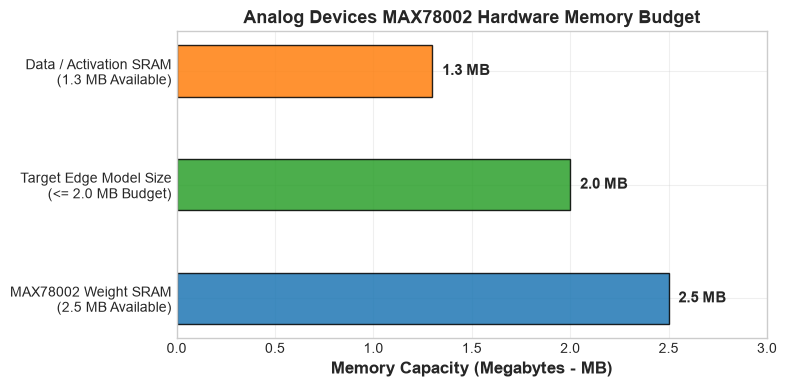

In [5]:
# Visualizing MAX78002 Edge-AI Hardware Resource Budget
labels = ['MAX78002 Weight SRAM\n(2.5 MB Available)', 'Target Edge Model Size\n(<= 2.0 MB Budget)', 'Data / Activation SRAM\n(1.3 MB Available)']
values = [2.5, 2.0, 1.3]
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, values, color=colors, height=0.45, edgecolor='black', alpha=0.85)
ax.set_xlabel("Memory Capacity (Megabytes - MB)", fontweight='bold')
ax.set_title("Analog Devices MAX78002 Hardware Memory Budget", fontweight='bold')
ax.grid(True, alpha=0.3)

for bar, val in zip(bars, values):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2, f"{val:.1f} MB", va='center', fontweight='bold')

ax.set_xlim(0, 3.0)
plt.tight_layout()
plt.show()

## 1.6 Risks and Challenges

We identify four critical technical risks for the project and formulate concrete mitigations:

| # | Risk | Why is it important? | Proposed Mitigation |
| :---: | :--- | :--- | :--- |
| **1** | **Inter-Patient Generalization Collapse** | Patient-specific morphology can cause models to memorize individual subjects, failing catastrophically on unseen patients. | Enforce strict patient-independent de Chazal benchmark partitioning (DS1 Train: 17 records, DS1 Val: 5 records, DS2 Test: 22 records). Never split randomly by heartbeat. |
| **2** | **Minority Class Starvation (Severe Imbalance)** | Class N represents $89.5\%$ of data; Class F is $0.8\%$. Models can achieve $90\%$ accuracy while predicting zero ectopic beats. | Implement inverse class weighting in loss function, effective number weighting, and training-time data augmentation. |
| **3** | **Quantization Loss (FP32 $\to$ INT8)** | Converting weights to 8-bit integers can degrade decision boundaries for subtle ectopic classes (S and F). | Apply per-beat Z-score normalization clamped to $[-3.0, 3.0]$ to prevent saturation; explore Quantization-Aware Training (QAT). |
| **4** | **Toolchain Synthesis Incompatibility** | Models using unsupported operations cannot be synthesized onto the MAX78002 accelerator, violating project requirements. | Build a compact 1D CNN using exclusively supported layers: Conv1D, MaxPool, ReLU, and Linear, with fixed-size $(1, 256)$ inputs. |

In [6]:
# Display Formal Risk Matrix
risks_df = pd.DataFrame([
    {
        "Risk": "Inter-Patient Data Leakage",
        "Severity": "Critical",
        "Impact": "Artificially inflated test accuracy (99%) that fails completely in real clinical deployment",
        "Mitigation": "Enforce strict patient-level record partitioning (DS1 development vs DS2 test); zero subject overlap"
    },
    {
        "Risk": "Severe Class Imbalance",
        "Severity": "High",
        "Impact": "Model predicts majority Class N, ignoring rare life-threatening arrhythmias (Class V and F)",
        "Mitigation": "Employ inverse frequency class weights, weighted cross-entropy / focal loss, and training data augmentation"
    },
    {
        "Risk": "Quantization Accuracy Loss",
        "Severity": "Medium",
        "Impact": "INT8 fixed-point arithmetic on MAX78002 degrades sensitivity on subtle classes",
        "Mitigation": "Strict waveform amplitude clamping to [-3, 3] std devs, symmetric weight scaling, and QAT"
    },
    {
        "Risk": "MAX78002 Toolchain Rejection",
        "Severity": "Critical",
        "Impact": "Model cannot be synthesized for hardware deployment; assignment failure",
        "Mitigation": "Design strictly around MAX78002 CNN accelerator primitives (1D Conv, MaxPool, ReLU, Linear, fixed 256 samples)"
    }
])
display(risks_df)
print("\nCRISP-DM Stage 1 (Business & Application Understanding) Complete.")

,Risk,Severity,Impact,Mitigation
0,Inter-Patient Data Leakage,Critical,Artificially inflated test accuracy (99%) that...,Enforce strict patient-level record partitioni...
1,Severe Class Imbalance,High,"Model predicts majority Class N, ignoring rare...","Employ inverse frequency class weights, weight..."
2,Quantization Accuracy Loss,Medium,INT8 fixed-point arithmetic on MAX78002 degrad...,"Strict waveform amplitude clamping to [-3, 3] ..."
3,MAX78002 Toolchain Rejection,Critical,Model cannot be synthesized for hardware deplo...,Design strictly around MAX78002 CNN accelerato...



CRISP-DM Stage 1 (Business & Application Understanding) Complete.
